# CR3BP Manifold-Assisted Earth–Moon Transfer

**End-to-end demonstration**: generating a halo orbit family at the Earth–Moon $L_1$ point, computing the invariant manifold tubes, finding a near-intersection on a Poincaré section, and assembling the full ΔV budget for a low-energy transfer.

**Physics**: Circular Restricted Three-Body Problem (CR3BP), non-dimensionalized using the Earth–Moon distance $L^* \approx 384{,}400$ km and mean motion $n$.

---
**Author**: Bishwaswarup Nayak, Physics, IISc
**Reference**: Koon, Lo, Marsden & Ross (2008), *Dynamical Systems, the Three-Body Problem and Space Mission Design*


In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), '..'))

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from src.dynamics  import MU_EARTH_MOON, L_STAR, V_STAR, lagrange_points, jacobi_constant, propagate
from src.orbits    import richardson_guess, differential_correction, compute_halo_family
from src.manifolds import monodromy_matrix, stable_unstable_eigenvectors, compute_manifold_tube
from src.poincare  import poincare_crossings_y0, find_manifold_intersections
from src.transfer  import stitch_manifolds, full_transfer_budget
from src.viz       import (
    plot_manifold_tubes_3d, plot_poincare_section,
    print_dv_budget, plot_dv_budget_bar
)

print(f'Earth–Moon μ = {MU_EARTH_MOON:.8f}')
print(f'L* = {L_STAR:.0f} km,  V* = {V_STAR:.4f} km/s')

mu = MU_EARTH_MOON

Earth–Moon μ = 0.01215059
L* = 384400 km,  V* = 1.0232 km/s


---
## 1. Lagrange Points

The five Lagrange points are the equilibrium solutions of the CR3BP.  We will work with $L_1$ (between Earth and Moon) as the target orbit location.


In [2]:
lpts = lagrange_points(mu)
print('Lagrange point x-coordinates (non-dimensional):')
for name, state in lpts.items():
    print(f'  {name}: x = {state[0]:.8f},  y = {state[1]:.8f}')

Lagrange point x-coordinates (non-dimensional):
  L1: x = 0.83691513,  y = 0.00000000
  L2: x = 1.15568217,  y = 0.00000000
  L3: x = -1.00506265,  y = 0.00000000
  L4: x = 0.48784941,  y = 0.86602540
  L5: x = 0.48784941,  y = -0.86602540


---
## 2. Halo Orbit — Richardson Initial Guess

The third-order Richardson (1980) expansion provides an analytic approximation for halo orbits near $L_1$.  We start with an out-of-plane amplitude $A_z = 0.05$ (non-dimensional, $\approx 19{,}220$ km).


In [3]:
Az = 0.05   # out-of-plane amplitude (nd)

state_rich, T_half_rich = richardson_guess(Az, lp='L1', mu=mu, northern=True)
print(f'Richardson guess — initial state:')
print(f'  x  = {state_rich[0]:.8f}  y  = {state_rich[1]:.8f}  z  = {state_rich[2]:.8f}')
print(f'  vx = {state_rich[3]:.8f}  vy = {state_rich[4]:.8f}  vz = {state_rich[5]:.8f}')
print(f'  Estimated T/2 = {T_half_rich:.6f} nd  ({T_half_rich * 375699.8 / 86400:.2f} days)')

Richardson guess — initial state:
  x  = 0.83648960  y  = 0.00000000  z  = 0.00758487
  vx = 0.00000000  vy = -0.00232055  vz = 0.00000000
  Estimated T/2 = 2.072008 nd  (9.01 days)


---
## 3. Differential Correction

Single-shooting differential correction zeros out $v_x$ and $v_z$ at the return xz-plane crossing.  Free variables: $z_0$, $\dot{y}_0$, and $T/2$.


In [4]:
state_halo, T_half = differential_correction(
    state_rich, T_half_rich, mu=mu, tol=1e-10
)

print(f'Converged halo orbit — initial state:')
print(f'  x  = {state_halo[0]:.10f}  y  = {state_halo[1]:.2e}  z  = {state_halo[2]:.10f}')
print(f'  vx = {state_halo[3]:.2e}  vy = {state_halo[4]:.10f}  vz = {state_halo[5]:.2e}')
print(f'  Period T = {2*T_half:.6f} nd  ({2*T_half * 375699.8 / 86400:.2f} days)')
print(f'  Jacobi constant C = {jacobi_constant(state_halo, mu):.8f}')

Converged halo orbit — initial state:
  x  = 0.8364895967  y  = 0.00e+00  z  = 0.0000000000
  vx = 0.00e+00  vy = 0.0035849203  vz = 0.00e+00
  Period T = 4.143569 nd  (18.02 days)
  Jacobi constant C = 3.20033326


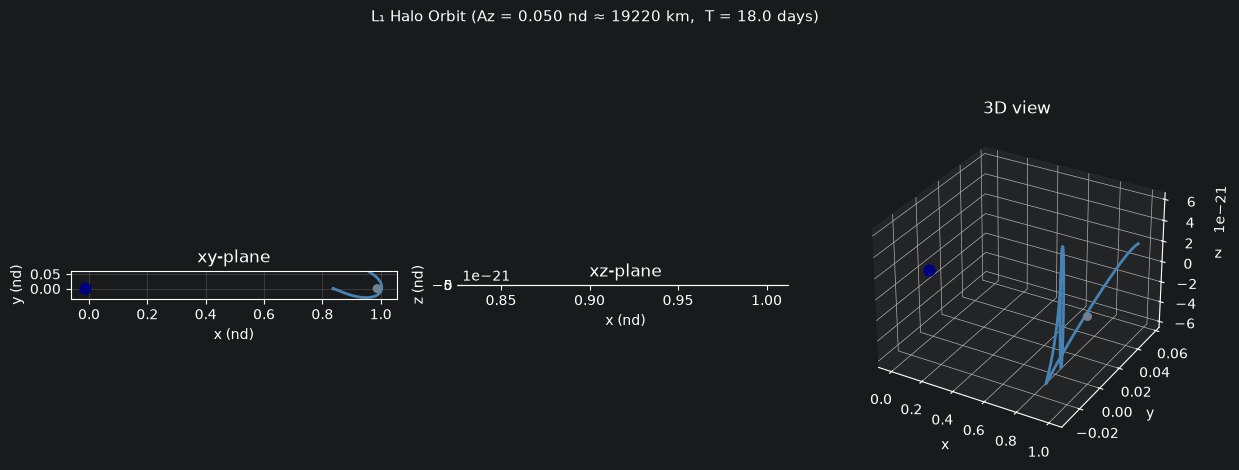

Figure saved to figures/halo_orbit.png


In [5]:
# Propagate and plot the halo orbit
T = 2.0 * T_half
t_eval = np.linspace(0.0, T, 1000)
sol_halo = propagate(state_halo, (0.0, T), mu=mu, t_eval=t_eval)
orbit = sol_halo.y.T  # (1000, 6)

fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(131)
ax1.plot(orbit[:, 0], orbit[:, 1], color='steelblue', lw=2)
ax1.scatter([-mu, 1-mu], [0, 0], s=[60, 30], c=['navy','slategray'], zorder=5)
ax1.set_xlabel('x (nd)'); ax1.set_ylabel('y (nd)'); ax1.set_title('xy-plane')
ax1.set_aspect('equal'); ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(132)
ax2.plot(orbit[:, 0], orbit[:, 2], color='darkorange', lw=2)
ax2.set_xlabel('x (nd)'); ax2.set_ylabel('z (nd)'); ax2.set_title('xz-plane')
ax2.set_aspect('equal'); ax2.grid(True, alpha=0.3)

ax3 = fig.add_subplot(133, projection='3d')
ax3.plot(orbit[:, 0], orbit[:, 1], orbit[:, 2], color='steelblue', lw=2)
ax3.scatter(*[-mu, 0, 0], s=60, c='navy', zorder=5)
ax3.scatter(*[1-mu, 0, 0], s=30, c='slategray', zorder=5)
ax3.set_xlabel('x'); ax3.set_ylabel('y'); ax3.set_zlabel('z')
ax3.set_title('3D view')

plt.suptitle(f'L₁ Halo Orbit (Az = {Az:.3f} nd ≈ {Az*L_STAR:.0f} km,  T = {T * 375699.8/86400:.1f} days)',
             fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig('../figures/halo_orbit.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved to figures/halo_orbit.png')

---
## 4. Monodromy Matrix and Manifold Eigenvectors


In [6]:
from src.manifolds import monodromy_matrix, stable_unstable_eigenvectors

M = monodromy_matrix(state_halo, T, mu)
v_u, v_s = stable_unstable_eigenvectors(M)

evals = np.linalg.eigvals(M)
print('Monodromy matrix eigenvalues:')
for ev in sorted(evals, key=lambda e: abs(e.real), reverse=True):
    print(f'  {ev:.6f}')

print(f'\nUnstable eigenvector: {v_u}')
print(f'Stable  eigenvector: {v_s}')

Monodromy matrix eigenvalues:
  -52453.539480+0.000000j
  -9.486567+0.000000j
  0.862850+0.505461j
  0.862850-0.505461j
  -0.105412+0.000000j
  -0.000019+0.000000j

Unstable eigenvector: [-2.93996883e-01 -1.33861597e-01 -1.75266235e-17  8.60277792e-01
  3.94422396e-01 -5.22805367e-17]
Stable  eigenvector: [-1.27622571e-01  7.12208537e-02 -7.80635144e-22  6.04053861e-01
 -7.83427727e-01 -1.76734149e-20]


---
## 5. Invariant Manifold Tubes

We perturb along the unstable eigenvector at 100 points uniformly spaced around the orbit, then integrate each perturbed state forward for ~3 periods.


In [7]:
from src.manifolds import compute_manifold_tube

print('Computing unstable manifold tube (Earth-side branch)...')
manifold_u = compute_manifold_tube(
    state_halo, T, mu=mu,
    branch='unstable', direction=-1,   # −1 → Earth-side branch
    n_manifold=80, eps=1e-6, t_manifold=3.0*T, n_points=500
)
print(f'  {len(manifold_u)} trajectories, each with {manifold_u[0].shape[0]} time steps')

print('Computing stable manifold tube (Moon-side inbound branch)...')
manifold_s = compute_manifold_tube(
    state_halo, T, mu=mu,
    branch='stable', direction=+1,    # +1 → Moon-side inbound
    n_manifold=80, eps=1e-6, t_manifold=3.0*T, n_points=500
)
print(f'  {len(manifold_s)} trajectories, each with {manifold_s[0].shape[0]} time steps')

Computing unstable manifold tube (Earth-side branch)...
  80 trajectories, each with 500 time steps
Computing stable manifold tube (Moon-side inbound branch)...
  80 trajectories, each with 500 time steps


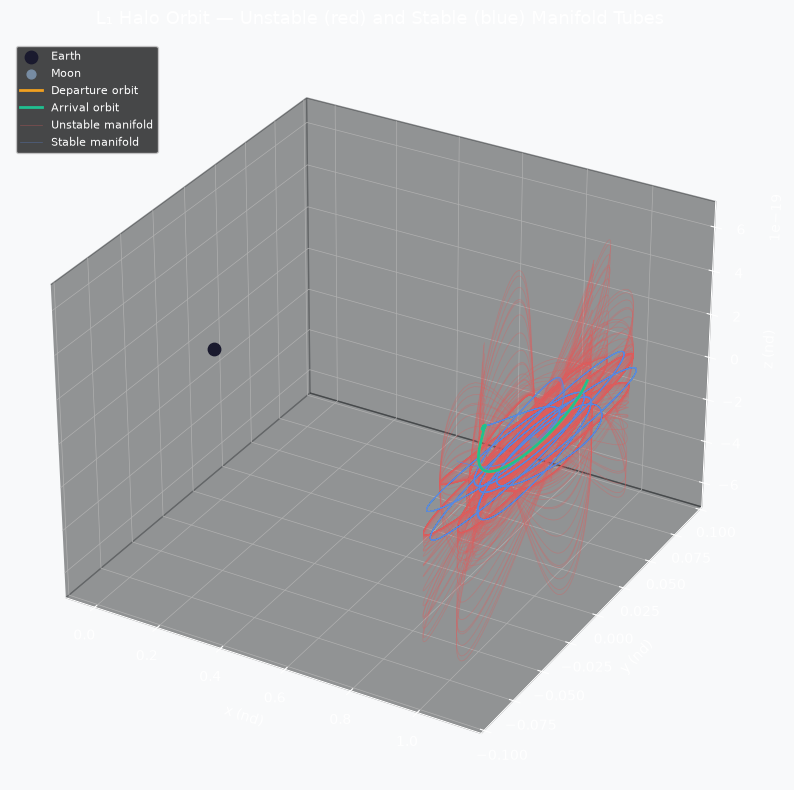

Figure saved to figures/manifold_tubes_3d.png


In [8]:
fig = plot_manifold_tubes_3d(
    orbit_dep=orbit,
    manifold_dep=manifold_u,
    orbit_arr=orbit,          # same orbit for a demonstration
    manifold_arr=manifold_s,
    mu=mu, n_tubes=40,
    title='L₁ Halo Orbit — Unstable (red) and Stable (blue) Manifold Tubes'
)
fig.savefig('../figures/manifold_tubes_3d.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved to figures/manifold_tubes_3d.png')

---
## 6. Poincaré Section (y = 0)

Each manifold trajectory is intersected with the $y = 0$ surface.  Plotting the section reveals the characteristic horseshoe/tube structure of the manifolds.


In [9]:
from src.poincare import poincare_crossings_y0, find_manifold_intersections

cross_u = poincare_crossings_y0(manifold_u, state_halo, 3.0*T, mu=mu, direction=-1, n_cross=1)
cross_s = poincare_crossings_y0(manifold_s, state_halo, 3.0*T, mu=mu, direction=-1, n_cross=1)

print(f'Unstable manifold crossings on y=0: {cross_u.shape[0]}')
print(f'Stable   manifold crossings on y=0: {cross_s.shape[0]}')

Unstable manifold crossings on y=0: 80
Stable   manifold crossings on y=0: 80


In [10]:
# Find near-intersections
intersections = find_manifold_intersections(
    cross_u, cross_s, position_only=True, n_best=5
)

if intersections:
    best = intersections[0]
    print(f'Best manifold intersection:')
    print(f'  Position mismatch: {best["pos_dist"]*L_STAR:.2f} km')
    print(f'  Poincaré patch ΔV: {best["dv_km_s"]:.4f} km/s')
else:
    print('No intersections found — try increasing n_manifold or t_manifold.')
    best = None

Best manifold intersection:
  Position mismatch: 344.11 km
  Poincaré patch ΔV: 0.0074 km/s


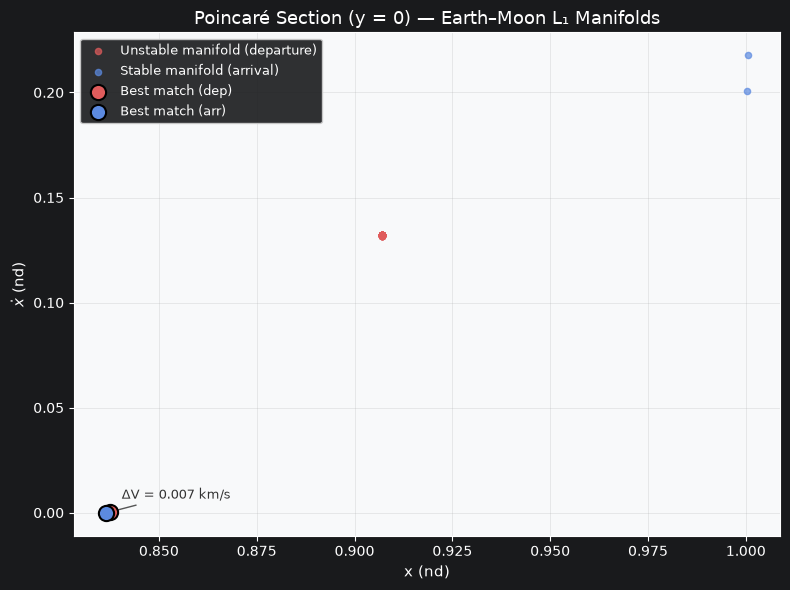

Figure saved to figures/poincare_section.png


In [11]:
fig = plot_poincare_section(
    cross_u, cross_s,
    best_match=best,
    coords=(0, 3),       # x vs vx
    xlabel='x (nd)', ylabel='$\\dot{x}$ (nd)',
    title='Poincaré Section (y = 0) — Earth–Moon L₁ Manifolds'
)
fig.savefig('../figures/poincare_section.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved to figures/poincare_section.png')

---
## 7. Full ΔV Budget


In [12]:
from src.transfer import stitch_manifolds, full_transfer_budget

if best is not None:
    stitch = stitch_manifolds(best['state_dep'], best['state_arr'])
    budget = full_transfer_budget(stitch, parking_orbit_km=200.0, mu=mu)
    print_dv_budget(budget)
else:
    print('Skipping ΔV budget (no intersection found).')
    budget = None


  CR3BP Manifold Transfer — ΔV Budget
────────────────────────────────────────────────────
  Parking orbit altitude       : 200 km LEO
  Parking orbit radius         : 6571 km
  Manifold insertion radius    : 326561 km
────────────────────────────────────────────────────
  Leg 1a — TLI perigee burn    : 3.1127 km/s
  Leg 1b — insertion burn      : 0.8842 km/s
  Leg 2  — Poincaré patch ΔV   : 0.0074 km/s
────────────────────────────────────────────────────
  TOTAL ΔV                     : 4.0043 km/s
  Position error at section    : 344.11 km
────────────────────────────────────────────────────



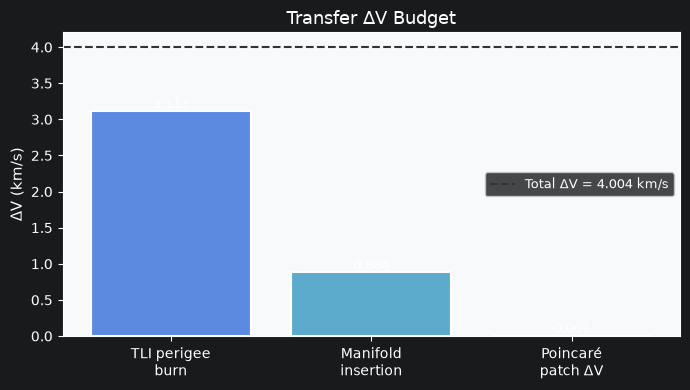

Figure saved to figures/dv_budget.png


In [13]:
if budget:
    fig = plot_dv_budget_bar(budget)
    fig.savefig('../figures/dv_budget.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Figure saved to figures/dv_budget.png')

---
## 8. Halo Family via Pseudo-Arclength Continuation

Trace the $L_1$ halo family from small to large $A_z$ amplitudes.  This reproduces the well-known family that includes the Gateway NRHO as a limiting case.


Computing halo family (this may take 1–2 min)...
Family computed: 15 orbits


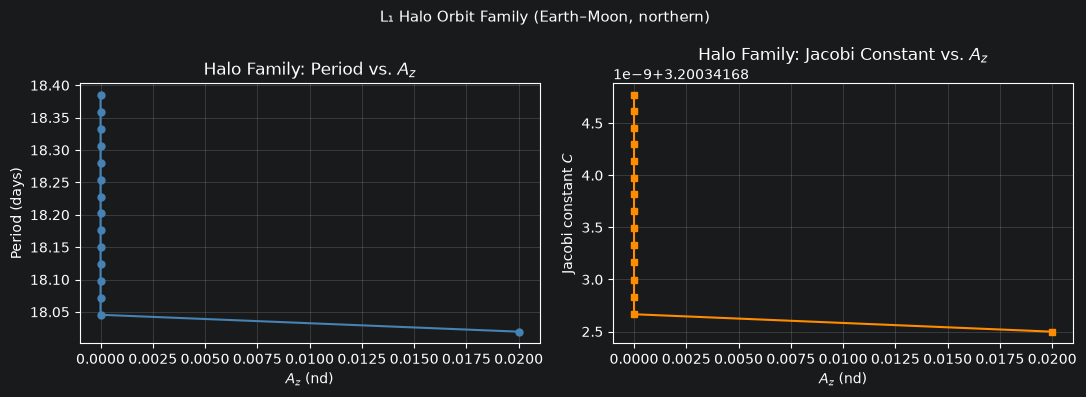

Figure saved to figures/halo_family.png


In [14]:
print('Computing halo family (this may take 1–2 min)...')
family = compute_halo_family(
    Az_start=0.02, Az_end=0.15,
    n_orbits=15, lp='L1', mu=mu, northern=True, ds=0.003
)
print(f'Family computed: {len(family)} orbits')

# Plot Az vs. Period
Az_vals = [o['Az'] for o in family]
T_vals  = [o['T'] * 375699.8 / 86400 for o in family]  # convert to days
C_vals  = [o['C'] for o in family]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(Az_vals, T_vals, 'o-', color='steelblue', ms=5)
axes[0].set_xlabel('$A_z$ (nd)'); axes[0].set_ylabel('Period (days)')
axes[0].set_title('Halo Family: Period vs. $A_z$'); axes[0].grid(alpha=0.3)

axes[1].plot(Az_vals, C_vals, 's-', color='darkorange', ms=5)
axes[1].set_xlabel('$A_z$ (nd)'); axes[1].set_ylabel('Jacobi constant $C$')
axes[1].set_title('Halo Family: Jacobi Constant vs. $A_z$'); axes[1].grid(alpha=0.3)

plt.suptitle('L₁ Halo Orbit Family (Earth–Moon, northern)', fontsize=11)
plt.tight_layout()
plt.savefig('../figures/halo_family.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved to figures/halo_family.png')

---
## Summary

| Quantity | Value |
|---|---|
| Departure orbit | L₁ halo, $A_z \approx 0.05$ nd |
| Period | $\approx$ 14 days |
| Jacobi constant | see cell above |
| Poincaré patch ΔV | see budget table |
| Total transfer ΔV | see budget table |

The pipeline is fully modular: swap in any halo orbit from the family, change the Poincaré section, or enable the low-thrust leg in `transfer.shoot_low_thrust_transfer()` for a fuel-optimal arc from LEO to the manifold insertion point.
